In [1]:
import scipy as sp
#from scipy.misc import derivative
from scipy.special import jv, hankel2, hankel1, yv, jvp, yvp, factorial
import numpy as np
import matplotlib.pyplot as plt
from numpy import sqrt, linspace, zeros, ones, pi, exp, conj, argmin, unravel_index, log, einsum, tan, log10, atan, cosh
import torch
import warnings
warnings.filterwarnings("ignore")
from utils import h_z_cpa, h_z_cpa_denominator, h_z_cpa_numerator, e_z_cpa, e_z_cpa_numerator, hl2_prime, hl1_prime, hbar, c, alpha, graphene_conductivity
plt.rc('font', size=14)          # controls default text sizes

### This notebook recreates select figures from the paper [Coherent virtual absorption based on complex zero excitation for ideal light capturing](https://opg.optica.org/directpdfaccess/c81ceff5-9917-4781-82436a01778fb4cf_377272/optica-4-12-1457.pdf?da=1&id=377272&seq=0&mobile=no). We first start with the slab calculation (Figure 1b)

In [2]:
def reflection(n, kd):
    r_num = (n**2-1)*(exp(2j*n*kd)-1)
    r_t_denom = (n+1)**2-((n-1)**2)*exp(2j*n*kd)
    return r_num/r_t_denom
def transmission(n, kd):
    t_num = 4*n*exp(1j*n*kd)
    r_t_denom = (n+1)**2-((n-1)**2)*exp(2j*n*kd)
    return t_num/r_t_denom

In [3]:
N_imag = 5000; N_real = 10000
x_real = linspace(1, 8, N_real); x_imag = linspace(0.1, 0.4, N_imag)
x = x_real.reshape((N_real, 1)).repeat(N_imag, axis=1) + 1j*x_imag.reshape((1, N_imag)).repeat(N_real, axis=0)

In [4]:
n_slab = 3 # index of refraction of the slab
t = transmission(n_slab, x); r = reflection(n_slab, x) 
s_symmetric = r + t; s_anti_symmetric = r - t; # scattering amplitudes for symmetric and anti-symmetric illumination

In [5]:
minima_symmetric = log(np.abs(s_symmetric)**2).min(axis=1); argminima_symmetric = log(np.abs(s_symmetric)**2).argmin(axis=1)

qnm_idxs_symmetric = np.where(minima_symmetric < -15) # -15 is the required threshold to get three distinct CPA zeros
qnm_real_symmetric_v = x_real[qnm_idxs_symmetric]; qnm_imag_symmetric_v = x_imag[argminima_symmetric[qnm_idxs_symmetric]]

minima_anti_symmetric = log(np.abs(s_anti_symmetric)**2).min(axis=1); argminima_anti_symmetric = log(np.abs(s_anti_symmetric)**2).argmin(axis=1)

qnm_anti_symmetric_idxs = np.where(minima_anti_symmetric < -14.526) # Threshold required for four distinct CPA zeros
qnm_real_anti_symmetric_v = x_real[qnm_anti_symmetric_idxs]; qnm_imag_anti_symmetric_v = x_imag[argminima_anti_symmetric[qnm_anti_symmetric_idxs]]

### Note that for a slab we may find the positions of the CPA zeros in the complex plane analytically. From Equation 7 of [Coherent Perfect Absorbers: Time-Reversed Lasers](https://journals.aps.org/prl/pdf/10.1103/PhysRevLett.105.053901?casa_token=5F_u_EJ3hGMAAAAA%3AIrw8ZzzHL6Y6dc2OMfazBSis2mJCC-EwtreeP75brDaDy5SBMiqNspzswKjNKi-rtKKbqTi_WLDiYA), we see that we must have $e^{inkd}=\pm(n-1)/(n+1)$. Since $n$ is real valued here, we define $k=k'+ik''$, which gives us $e^{-nk''d}=(n-1)/(n+1)$ and $e^{ink'd}=\pm 1$. Thus, $k'd=\Re(kd)=m\pi/n$ for $m$ any integer and $k''d=\Im(kd)=-(1/n)\log((n-1)/n+1)$

Locations of the real parts of the zeros for the symmetric channel:  [2.09420942 4.18881888 6.28342834]
Locations of the real parts of the zeros for the anti-symmetric channel:  [1.04690469 3.14151415 5.23612361 7.330033  ]


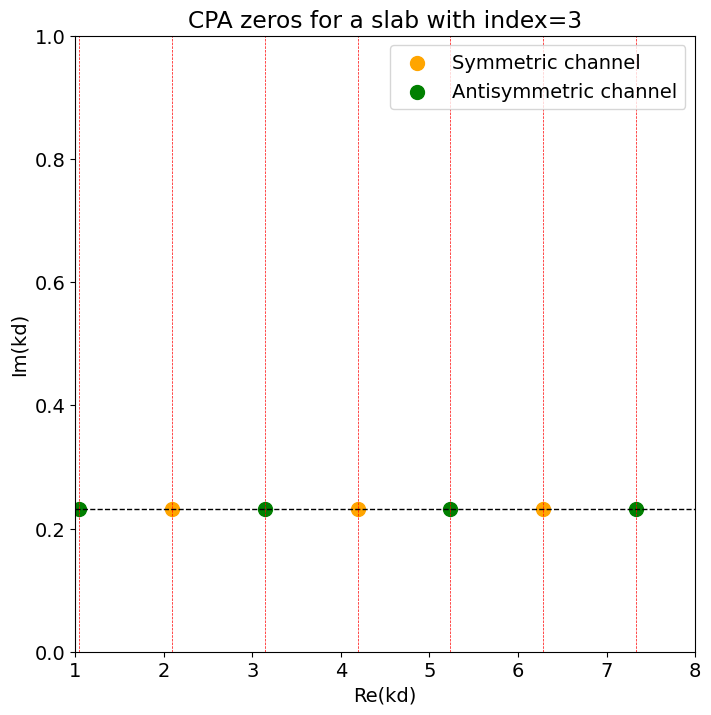

In [7]:
s=100
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(qnm_real_symmetric_v, qnm_imag_symmetric_v, color="Orange", s=s, label="Symmetric channel")
ax.scatter(qnm_real_anti_symmetric_v, qnm_imag_anti_symmetric_v, color="Green", s=s, label="Antisymmetric channel")
ax.hlines([-log((n_slab-1)/(n_slab+1))/n_slab], x_real.min(), x_real.max(), color="black", linewidth=1, linestyle="dashed")
ax.vlines([m*pi/n_slab for m in range(0, 10)], 0, 1, color="red", linestyle="dashed", linewidth=0.5)
ax.set_xlabel("Re(kd)")
ax.set_ylabel("Im(kd)")
ax.set_title(f"CPA zeros for a slab with index={n_slab}")
ax.set_ylim(0, 1)
ax.set_xlim(1, 8);
ax.legend();
print("Locations of the real parts of the zeros for the symmetric channel: ", qnm_real_symmetric_v)
print("Locations of the real parts of the zeros for the anti-symmetric channel: ", qnm_real_anti_symmetric_v)

### Now we move on to the case of TM modes of a cylinder (Figure 4 of the paper)

In [2]:
n_cylinder = 2; l = 0; N_real = 2000; N_imag = 2000
x_real = linspace(1, 8, N_real); x_imag = linspace(0.1, 0.4, N_imag)
x = x_real.reshape((N_real, 1)).repeat(N_imag, axis=1) + 1j*x_imag.reshape((1, N_imag)).repeat(N_real, axis=0)
s_tm = h_z_cpa(l, x, n_cylinder**2);

### Uncomment the cell below to see a heat map of the mode condition

In [3]:
#fig, ax = plt.subplots(figsize=(10, 5))
#ax.imshow(log(np.abs(s_tm)**2).T, origin="lower");

In [4]:
minima = log(np.abs(s_tm)**2).min(axis=1); argminima = log(np.abs(s_tm)**2).argmin(axis=1)
qnm_idxs = np.where(minima < -11) # Threshold set by requiring five distinct zeros
qnm_real_v = x_real[qnm_idxs]; qnm_imag_v = x_imag[argminima[qnm_idxs]]

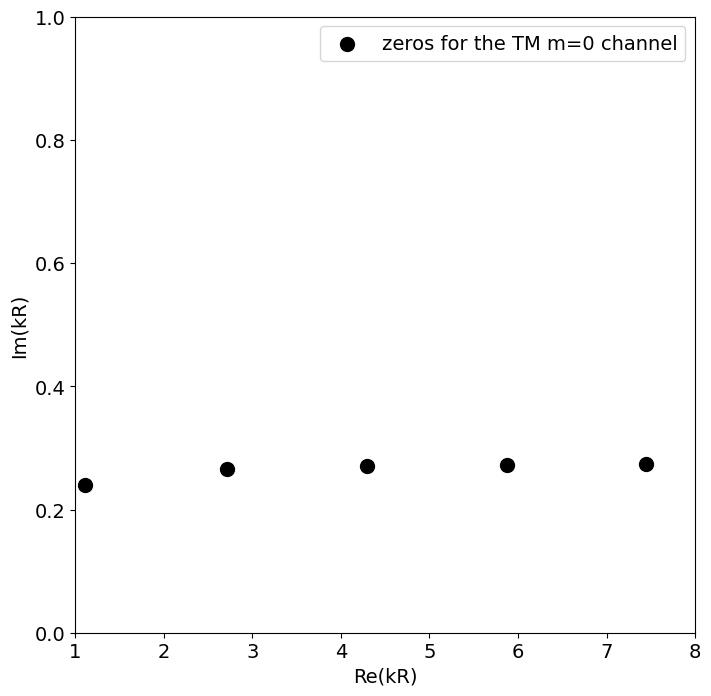

In [5]:
s=100
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(qnm_real_v, qnm_imag_v, s=s, color="black", label="zeros for the TM m=0 channel")
ax.set_ylim(0, 1)
ax.set_xlim(1, 8);
ax.set_xlabel("Re(kR)")
ax.set_ylabel("Im(kR)");
ax.legend();